# 📊 Comparaison : Avec vs Sans Variables Démographiques (Genre & Statut Marital)

Ce notebook compare les performances du **modèle Random Forest optimisé** lorsqu'il est entraîné sur deux jeux de données :

- **Dataset complet** (`prepared_data.csv`) : inclut le genre et le statut marital
- **Dataset réduit** (`prepared_data_no_gender_marital_status.csv`) : sans genre ni statut marital

L'objectif est de mesurer l'impact de la suppression de ces variables démographiques sur la capacité prédictive du modèle.

> ⚠️ Les deux modèles utilisent les **mêmes hyperparamètres optimaux** issus du notebook `10_optimization.ipynb`.

## 1. 📦 Imports & Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import pickle
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Style global
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_theme(style="whitegrid", palette="muted")

COLORS = {
    'full':    '#2E86AB',   # Dataset complet (avec démographiques)
    'reduced': '#E84855',   # Dataset réduit (sans démographiques)
    'success': '#3BB273',
    'warning': '#F6AE2D',
    'neutral': '#8D99AE',
    'bg':      '#F8F9FA',
}

DATA   = "Data/"
SEED   = 42
TEST_SIZE = 0.2

print("✅ Imports OK")
print(f"   Seed         : {SEED}")
print(f"   Test size    : {TEST_SIZE*100:.0f}%")

✅ Imports OK
   Seed         : 42
   Test size    : 20%


## 2. 📂 Chargement des Données

In [2]:
# ── Chargement des deux datasets ────────────────────────────────────────────
df_full    = pd.read_csv(DATA + "prepared_data.csv")
df_reduced = pd.read_csv(DATA + "prepared_data_no_gender_marital_status.csv")

# ── Colonnes supprimées ──────────────────────────────────────────────────────
removed_cols = sorted(set(df_full.columns) - set(df_reduced.columns))

print("=== Dataset COMPLET (avec genre & statut marital) ===")
print(f"  Shape  : {df_full.shape}")
print(f"  Cible  : {df_full['Attrition'].value_counts().to_dict()}")

print("\n=== Dataset RÉDUIT (sans genre & statut marital) ===")
print(f"  Shape  : {df_reduced.shape}")
print(f"  Cible  : {df_reduced['Attrition'].value_counts().to_dict()}")

print(f"\n🗑️  Colonnes retirées ({len(removed_cols)}) :")
for c in removed_cols:
    print(f"   • {c}")

=== Dataset COMPLET (avec genre & statut marital) ===
  Shape  : (4410, 47)
  Cible  : {0: 3699, 1: 711}

=== Dataset RÉDUIT (sans genre & statut marital) ===
  Shape  : (4410, 42)
  Cible  : {0: 3699, 1: 711}

🗑️  Colonnes retirées (5) :
   • Gender_Female
   • Gender_Male
   • MaritalStatus_Divorced
   • MaritalStatus_Married
   • MaritalStatus_Single


## 3. 🔧 Chargement des Hyperparamètres Optimaux & Entraînement

On récupère les **hyperparamètres optimaux** issus de l'optimisation bayésienne, puis on entraîne un modèle indépendant sur chacun des deux datasets avec le **même split train/test** (même `random_state`, même indice d'employés).

In [3]:
# ── Chargement des hyperparamètres sauvegardés ───────────────────────────────
try:
    with open(DATA + "final_model_results.pkl", "rb") as f:
        final_results = pickle.load(f)
    best_params = final_results["hyperparameters"]
    print("✅ Hyperparamètres chargés depuis final_model_results.pkl")
except FileNotFoundError:
    # Fallback : charger directement le modèle pkl et récupérer ses params
    with open(DATA + "final_optimized_model.pkl", "rb") as f:
        loaded_model = pickle.load(f)
    best_params = loaded_model.get_params()
    # Retirer les params non pertinents pour la reconstruction
    for k in ["warm_start", "oob_score", "verbose", "class_weight", "ccp_alpha",
              "max_leaf_nodes", "max_samples", "min_impurity_decrease",
              "min_weight_fraction_leaf", "n_jobs", "random_state"]:
        best_params.pop(k, None)
    print("✅ Hyperparamètres récupérés depuis final_optimized_model.pkl")

print("\n🔧 Hyperparamètres optimaux :")
for k, v in best_params.items():
    print(f"   {k:25s}: {v}")

✅ Hyperparamètres chargés depuis final_model_results.pkl

🔧 Hyperparamètres optimaux :
   bootstrap                : False
   max_depth                : 50
   max_features             : sqrt
   min_samples_leaf         : 1
   min_samples_split        : 4
   n_estimators             : 500


In [4]:
# ── Fonction utilitaire : préparer X/y + split ───────────────────────────────
def prepare_dataset(df, label):
    X = df.drop(columns=["Attrition", "EmployeeID"])
    y = df["Attrition"]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
    )
    print(f"[{label}] Train: {X_train.shape[0]} | Test: {X_test.shape[0]} | Features: {X_train.shape[1]}")
    return X_train, X_test, y_train, y_test

# ── Préparation des deux datasets ────────────────────────────────────────────
X_train_full,    X_test_full,    y_train_full,    y_test_full    = prepare_dataset(df_full,    "COMPLET")
X_train_reduced, X_test_reduced, y_train_reduced, y_test_reduced = prepare_dataset(df_reduced, "RÉDUIT ")

# ── Entraînement avec les hyperparamètres optimaux ───────────────────────────
rf_full    = RandomForestClassifier(**best_params, random_state=SEED, n_jobs=-1)
rf_reduced = RandomForestClassifier(**best_params, random_state=SEED, n_jobs=-1)

print("\n⏳ Entraînement en cours...")
import time

t0 = time.time()
rf_full.fit(X_train_full, y_train_full)
t_full = time.time() - t0

t0 = time.time()
rf_reduced.fit(X_train_reduced, y_train_reduced)
t_reduced = time.time() - t0

print(f"✅ Modèle COMPLET    entraîné en {t_full:.2f}s")
print(f"✅ Modèle RÉDUIT     entraîné en {t_reduced:.2f}s")

[COMPLET] Train: 3528 | Test: 882 | Features: 45
[RÉDUIT ] Train: 3528 | Test: 882 | Features: 40

⏳ Entraînement en cours...
✅ Modèle COMPLET    entraîné en 0.49s
✅ Modèle RÉDUIT     entraîné en 0.54s


## 4. 📋 Comparaison des Métriques

In [5]:
# ── Prédictions ──────────────────────────────────────────────────────────────
y_pred_full    = rf_full.predict(X_test_full)
y_proba_full   = rf_full.predict_proba(X_test_full)[:, 1]

y_pred_reduced  = rf_reduced.predict(X_test_reduced)
y_proba_reduced = rf_reduced.predict_proba(X_test_reduced)[:, 1]

# ── Calcul des métriques ─────────────────────────────────────────────────────
def compute_metrics(y_true, y_pred, y_proba, label):
    return {
        "Dataset"  : label,
        "Accuracy" : round(accuracy_score(y_true, y_pred), 4),
        "Precision": round(precision_score(y_true, y_pred), 4),
        "Recall"   : round(recall_score(y_true, y_pred), 4),
        "F1 Score" : round(f1_score(y_true, y_pred), 4),
        "AUC-ROC"  : round(roc_auc_score(y_true, y_proba), 4),
    }

metrics_full    = compute_metrics(y_test_full,    y_pred_full,    y_proba_full,    "Avec Genre & Statut Marital")
metrics_reduced = compute_metrics(y_test_reduced, y_pred_reduced, y_proba_reduced, "Sans Genre & Statut Marital")

comparison_df = pd.DataFrame([metrics_full, metrics_reduced]).set_index("Dataset")

# ── Delta ────────────────────────────────────────────────────────────────────
delta = comparison_df.loc["Sans Genre & Statut Marital"] - comparison_df.loc["Avec Genre & Statut Marital"]
comparison_df.loc["Δ (Réduit − Complet)"] = delta

print("=" * 70)
print("📋 COMPARAISON DES MÉTRIQUES — Avec vs Sans Variables Démographiques")
print("=" * 70)
print(comparison_df.to_string())
print()

# Interprétation rapide
for metric in ["Accuracy", "Precision", "Recall", "F1 Score", "AUC-ROC"]:
    d = delta[metric]
    sign = "🔺" if d > 0 else ("🔻" if d < 0 else "➡️")
    print(f"  {sign} {metric:10s}: {d:+.4f}")

📋 COMPARAISON DES MÉTRIQUES — Avec vs Sans Variables Démographiques
                             Accuracy  Precision  Recall  F1 Score  AUC-ROC
Dataset                                                                    
Avec Genre & Statut Marital    0.9966        1.0  0.9789    0.9893   0.9987
Sans Genre & Statut Marital    0.9966        1.0  0.9789    0.9893   0.9992
Δ (Réduit − Complet)           0.0000        0.0  0.0000    0.0000   0.0005

  ➡️ Accuracy  : +0.0000
  ➡️ Precision : +0.0000
  ➡️ Recall    : +0.0000
  ➡️ F1 Score  : +0.0000
  🔺 AUC-ROC   : +0.0005


## 5. 📊 Visualisation des Performances

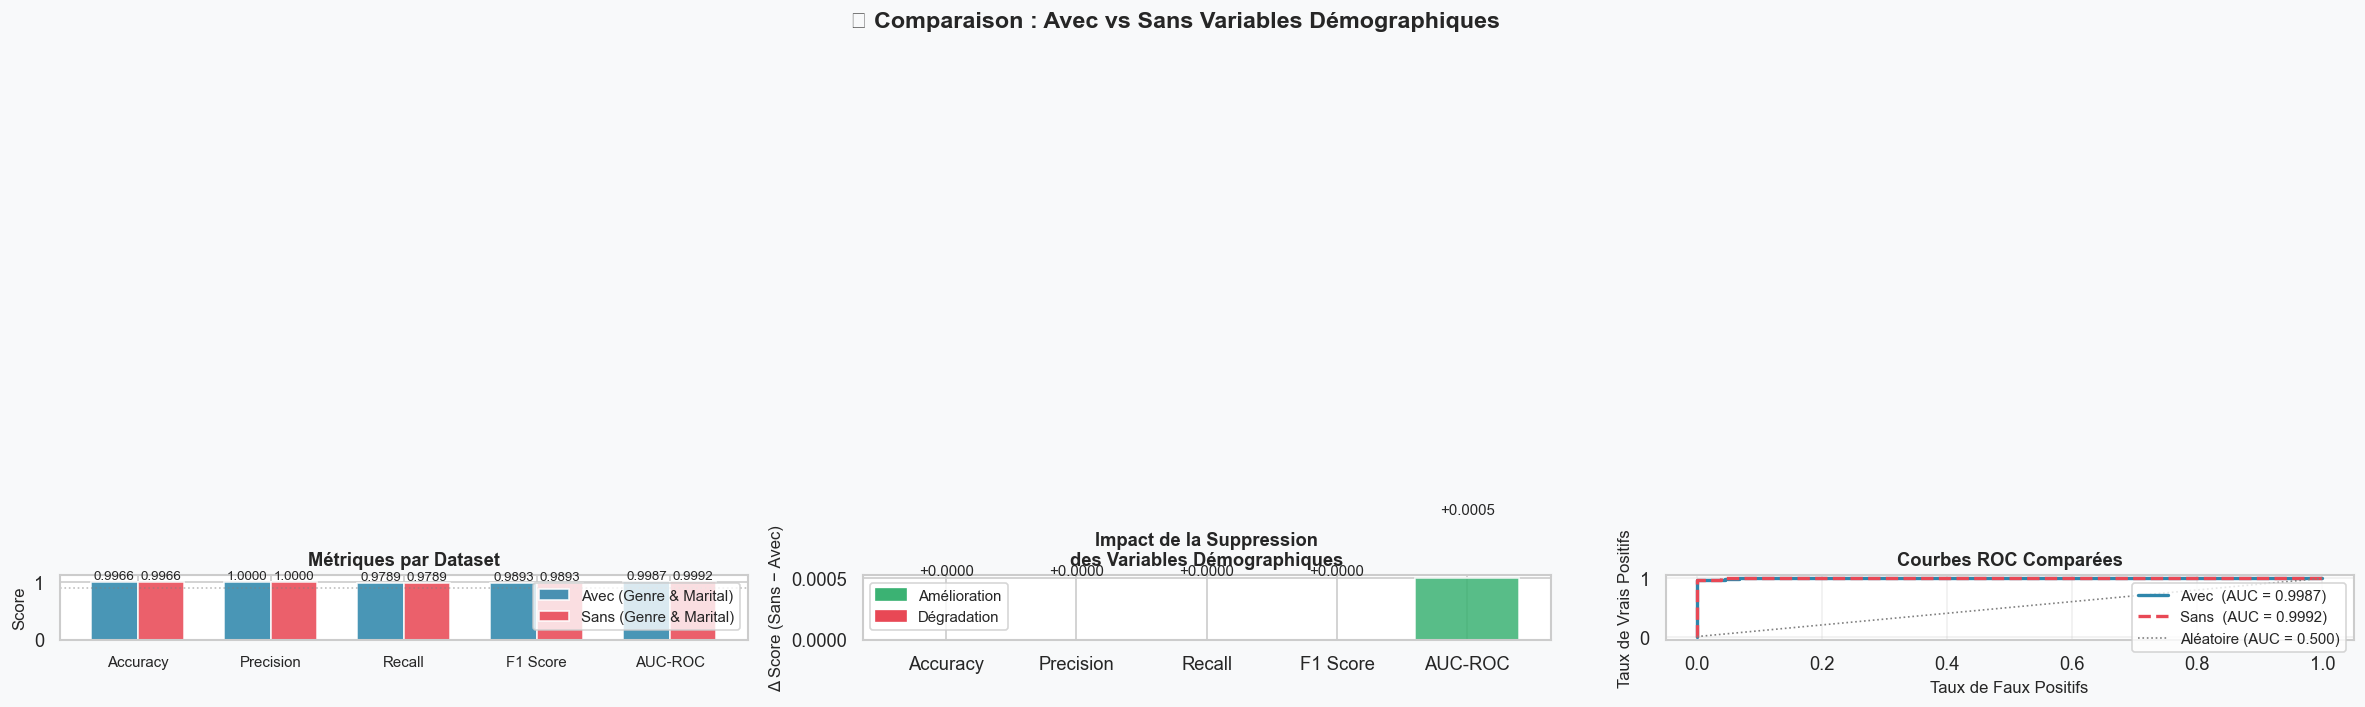

In [6]:
# ── Barres groupées : métriques comparées ────────────────────────────────────
metrics_list = ["Accuracy", "Precision", "Recall", "F1 Score", "AUC-ROC"]
vals_full    = [metrics_full[m]    for m in metrics_list]
vals_reduced = [metrics_reduced[m] for m in metrics_list]

x     = np.arange(len(metrics_list))
width = 0.35

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.patch.set_facecolor(COLORS['bg'])
fig.suptitle("📊 Comparaison : Avec vs Sans Variables Démographiques", fontsize=14, fontweight='bold')

# ── Subplot 1 : Barres groupées ──────────────────────────────────────────────
ax = axes[0]
b1 = ax.bar(x - width/2, vals_full,    width, label="Avec (Genre & Marital)", color=COLORS['full'],    alpha=0.87, edgecolor='white')
b2 = ax.bar(x + width/2, vals_reduced, width, label="Sans (Genre & Marital)", color=COLORS['reduced'], alpha=0.87, edgecolor='white')

for bar, v in zip(list(b1) + list(b2), vals_full + vals_reduced):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.003, f"{v:.4f}",
            ha='center', va='bottom', fontsize=8, rotation=0)

ax.set_xticks(x)
ax.set_xticklabels(metrics_list, fontsize=9)
ax.set_ylim(0.0, 1.12)
ax.set_ylabel("Score", fontsize=10)
ax.set_title("Métriques par Dataset", fontsize=11, fontweight='bold')
ax.legend(fontsize=9)
ax.set_facecolor('white')
ax.axhline(0.9, color='gray', linestyle=':', linewidth=1, alpha=0.5)

# ── Subplot 2 : Delta (gain/perte) ───────────────────────────────────────────
ax = axes[1]
delta_vals = [vals_reduced[i] - vals_full[i] for i in range(len(metrics_list))]
bar_colors = [COLORS['success'] if d >= 0 else COLORS['reduced'] for d in delta_vals]
bars = ax.bar(metrics_list, delta_vals, color=bar_colors, alpha=0.85, edgecolor='white')
ax.axhline(0, color='black', linewidth=1)
ax.set_ylabel("Δ Score (Sans − Avec)", fontsize=10)
ax.set_title("Impact de la Suppression\ndes Variables Démographiques", fontsize=11, fontweight='bold')
ax.set_facecolor('white')
for bar, v in zip(bars, delta_vals):
    ax.text(bar.get_x() + bar.get_width()/2,
            v + (0.0005 if v >= 0 else -0.0015),
            f"{v:+.4f}", ha='center',
            va='bottom' if v >= 0 else 'top', fontsize=9)
patches_d = [mpatches.Patch(color=COLORS['success'], label='Amélioration'),
             mpatches.Patch(color=COLORS['reduced'],  label='Dégradation')]
ax.legend(handles=patches_d, fontsize=9)

# ── Subplot 3 : Courbes ROC ──────────────────────────────────────────────────
ax = axes[2]
fpr_full, tpr_full, _ = roc_curve(y_test_full,    y_proba_full)
fpr_red,  tpr_red,  _ = roc_curve(y_test_reduced, y_proba_reduced)

auc_full = roc_auc_score(y_test_full,    y_proba_full)
auc_red  = roc_auc_score(y_test_reduced, y_proba_reduced)

ax.plot(fpr_full, tpr_full, color=COLORS['full'],    lw=2, label=f"Avec  (AUC = {auc_full:.4f})")
ax.plot(fpr_red,  tpr_red,  color=COLORS['reduced'], lw=2, label=f"Sans  (AUC = {auc_red:.4f})", linestyle='--')
ax.plot([0, 1], [0, 1], color='gray', lw=1, linestyle=':', label='Aléatoire (AUC = 0.500)')
ax.set_xlabel("Taux de Faux Positifs", fontsize=10)
ax.set_ylabel("Taux de Vrais Positifs", fontsize=10)
ax.set_title("Courbes ROC Comparées", fontsize=11, fontweight='bold')
ax.legend(fontsize=9)
ax.set_facecolor('white')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. 🔲 Matrices de Confusion Comparées

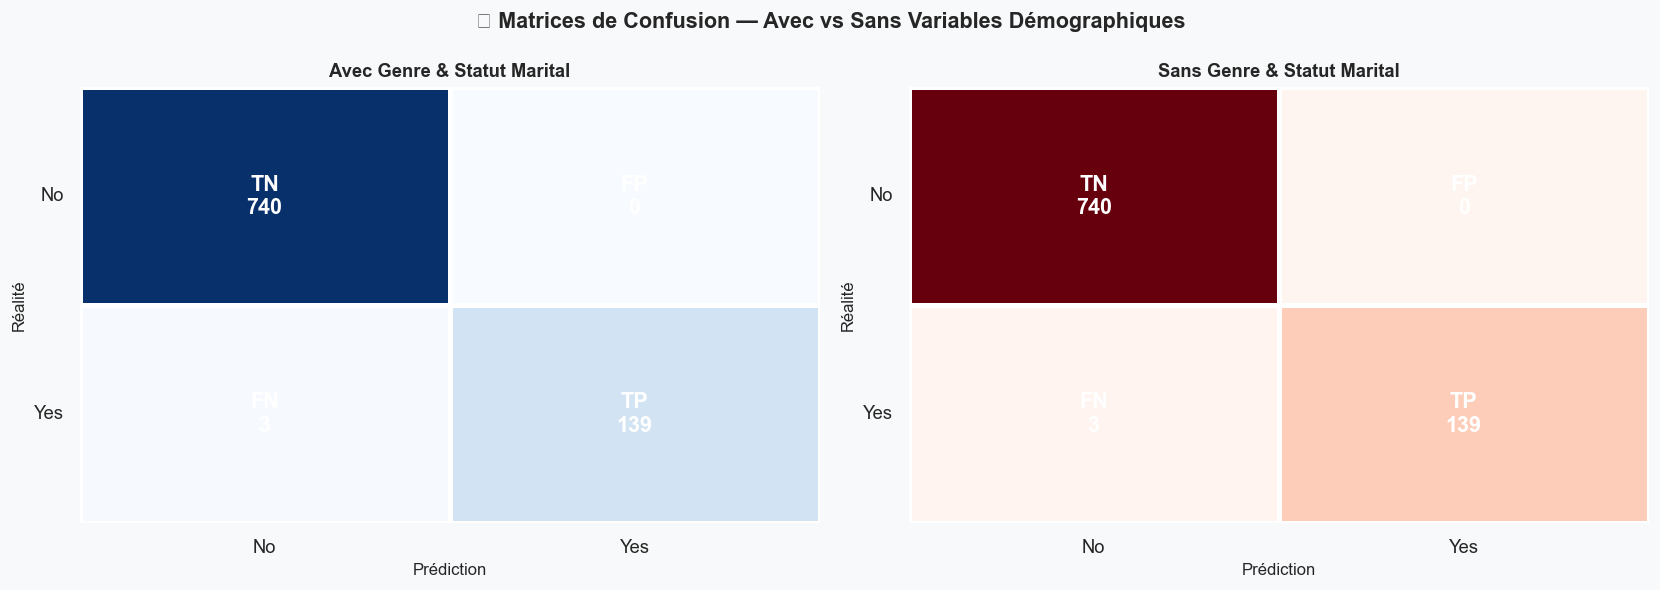

=== RAPPORT — Avec Genre & Statut Marital ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       740
           1       1.00      0.98      0.99       142

    accuracy                           1.00       882
   macro avg       1.00      0.99      0.99       882
weighted avg       1.00      1.00      1.00       882

=== RAPPORT — Sans Genre & Statut Marital ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       740
           1       1.00      0.98      0.99       142

    accuracy                           1.00       882
   macro avg       1.00      0.99      0.99       882
weighted avg       1.00      1.00      1.00       882



In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor(COLORS['bg'])
fig.suptitle("🔲 Matrices de Confusion — Avec vs Sans Variables Démographiques",
             fontsize=13, fontweight='bold')

for ax, (y_true, y_pred, title, cmap) in zip(axes, [
    (y_test_full,    y_pred_full,    "Avec Genre & Statut Marital", "Blues"),
    (y_test_reduced, y_pred_reduced, "Sans Genre & Statut Marital", "Reds"),
]):
    cm = confusion_matrix(y_true, y_pred)
    TN, FP, FN, TP = cm.ravel()

    sns.heatmap(cm, annot=False, fmt='d', cmap=cmap, cbar=False,
                linewidths=2, linecolor='white', ax=ax)

    # Annotations manuelles avec contexte
    labels = [
        (0.5, 0.5, f"TN\n{TN}", 'white'),
        (1.5, 0.5, f"FP\n{FP}", 'white'),
        (0.5, 1.5, f"FN\n{FN}", 'white'),
        (1.5, 1.5, f"TP\n{TP}", 'white'),
    ]
    for x_pos, y_pos, text, color in labels:
        ax.text(x_pos, y_pos, text, ha='center', va='center',
                fontsize=13, fontweight='bold', color=color)

    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel("Prédiction", fontsize=10)
    ax.set_ylabel("Réalité",    fontsize=10)
    ax.set_xticklabels(["No", "Yes"])
    ax.set_yticklabels(["No", "Yes"], rotation=0)

plt.tight_layout()
plt.show()

# Rapport de classification côte à côte
print("=== RAPPORT — Avec Genre & Statut Marital ===")
print(classification_report(y_test_full, y_pred_full))
print("=== RAPPORT — Sans Genre & Statut Marital ===")
print(classification_report(y_test_reduced, y_pred_reduced))

## 7. 🌲 Feature Importance — Comparaison

Top 20 variables les plus importantes pour chaque modèle, côte à côte.

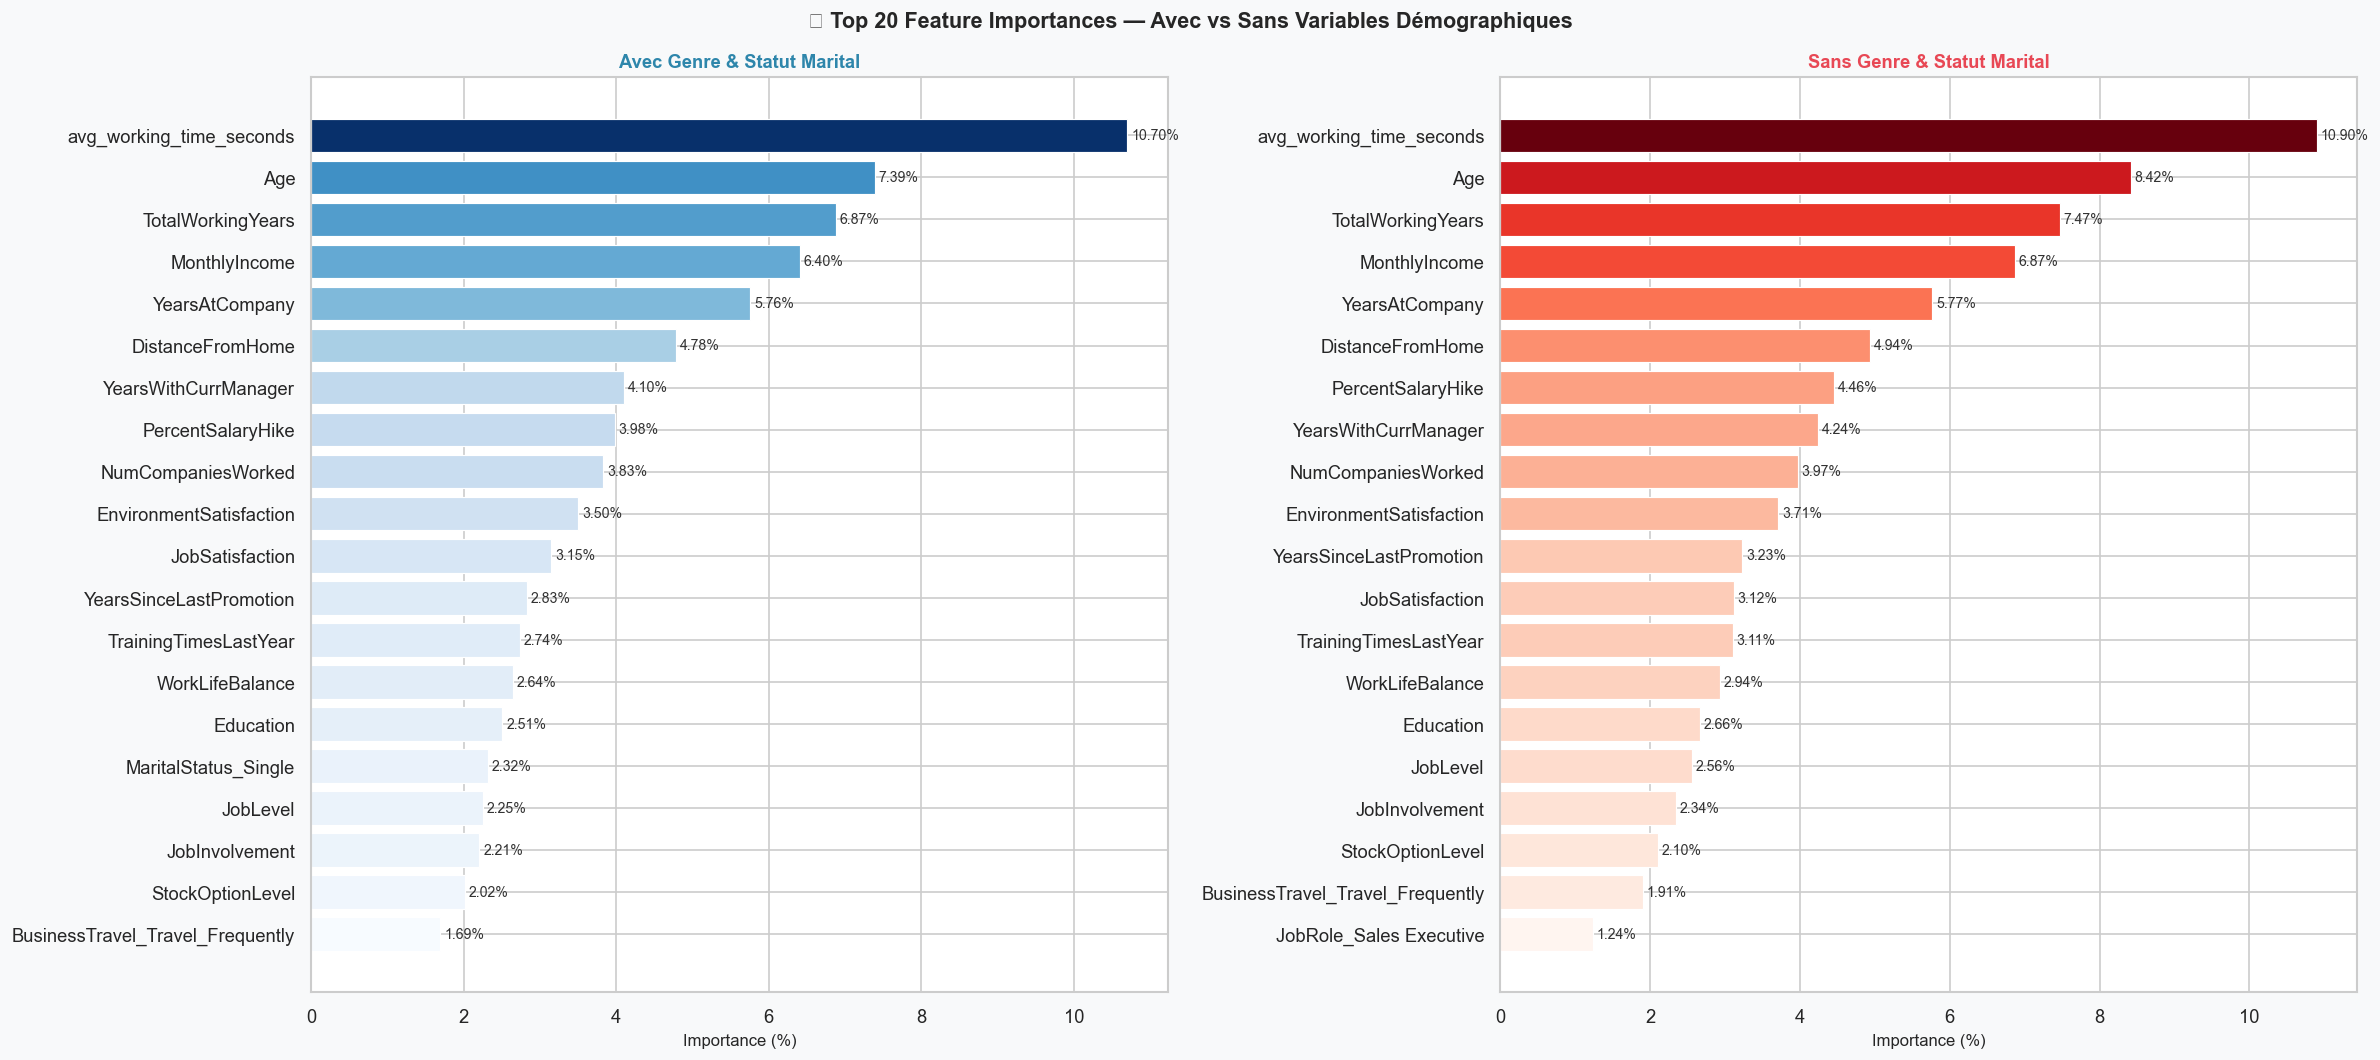

📊 Comparaison des rangs d'importance (Top 20) :
 rank_full                          feature  importance_full  rank_reduced  importance_reduced
         1         avg_working_time_seconds         0.106998           1.0            0.108966
         2                              Age         0.073854           2.0            0.084204
         3                TotalWorkingYears         0.068749           3.0            0.074719
         4                    MonthlyIncome         0.064047           4.0            0.068720
         5                   YearsAtCompany         0.057577           5.0            0.057697
         6                 DistanceFromHome         0.047781           6.0            0.049416
         7             YearsWithCurrManager         0.041036           8.0            0.042446
         8                PercentSalaryHike         0.039795           7.0            0.044603
         9               NumCompaniesWorked         0.038327           9.0            0.039719
  

In [8]:
TOP_N = 20

fi_full = (pd.DataFrame({'feature': X_test_full.columns,
                          'importance': rf_full.feature_importances_})
             .sort_values('importance', ascending=False)
             .head(TOP_N).sort_values('importance'))

fi_reduced = (pd.DataFrame({'feature': X_test_reduced.columns,
                              'importance': rf_reduced.feature_importances_})
                .sort_values('importance', ascending=False)
                .head(TOP_N).sort_values('importance'))

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
fig.patch.set_facecolor(COLORS['bg'])
fig.suptitle(f"🌲 Top {TOP_N} Feature Importances — Avec vs Sans Variables Démographiques",
             fontsize=13, fontweight='bold')

for ax, fi, title, color in [
    (axes[0], fi_full,    "Avec Genre & Statut Marital", COLORS['full']),
    (axes[1], fi_reduced, "Sans Genre & Statut Marital", COLORS['reduced']),
]:
    norm   = plt.Normalize(fi['importance'].min(), fi['importance'].max())
    colors = plt.cm.Blues(norm(fi['importance'].values)) if color == COLORS['full'] \
             else plt.cm.Reds(norm(fi['importance'].values))

    bars = ax.barh(fi['feature'], fi['importance'] * 100,
                   color=colors, edgecolor='white', linewidth=0.7)
    for bar, v in zip(bars, fi['importance'] * 100):
        ax.text(v + 0.05, bar.get_y() + bar.get_height()/2,
                f"{v:.2f}%", va='center', fontsize=8.5, color='#333')

    ax.set_xlabel("Importance (%)", fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold', color=color)
    ax.set_facecolor('white')

plt.tight_layout()
plt.show()

# ── Tableau comparatif des rangs ─────────────────────────────────────────────
rank_full    = (pd.DataFrame({'feature': X_test_full.columns,    'importance_full':    rf_full.feature_importances_})
                  .sort_values('importance_full',    ascending=False).reset_index(drop=True))
rank_full.index   += 1
rank_full.index.name = 'rank_full'

rank_reduced = (pd.DataFrame({'feature': X_test_reduced.columns, 'importance_reduced': rf_reduced.feature_importances_})
                  .sort_values('importance_reduced', ascending=False).reset_index(drop=True))
rank_reduced.index += 1
rank_reduced.index.name = 'rank_reduced'

merged_ranks = (rank_full.reset_index().merge(rank_reduced.reset_index(), on='feature', how='outer')
                .sort_values('rank_full'))

print("📊 Comparaison des rangs d'importance (Top 20) :")
print(merged_ranks.head(20).to_string(index=False))

## 8. 🔀 Validation Croisée — Stabilité des Scores

⏳ Validation croisée en cours (5-fold, scoring=f1)...

  Avec  Genre & Marital — F1 par fold : [np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0)]
  Moyenne : 1.0000 ± 0.0000

  Sans  Genre & Marital — F1 par fold : [np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0)]
  Moyenne : 1.0000 ± 0.0000


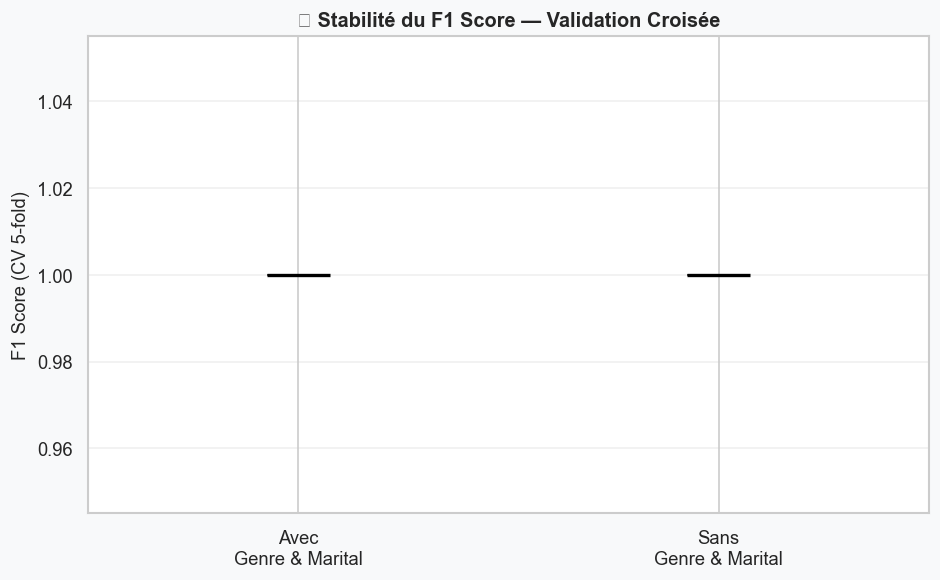

In [9]:
# Validation croisée 5-fold sur les données complètes (X entier, pas juste train)
X_full_all    = df_full.drop(columns=["Attrition", "EmployeeID"])
y_full_all    = df_full["Attrition"]
X_reduced_all = df_reduced.drop(columns=["Attrition", "EmployeeID"])
y_reduced_all = df_reduced["Attrition"]

rf_cv_full    = RandomForestClassifier(**best_params, random_state=SEED, n_jobs=-1)
rf_cv_reduced = RandomForestClassifier(**best_params, random_state=SEED, n_jobs=-1)

print("⏳ Validation croisée en cours (5-fold, scoring=f1)...")
scores_full    = cross_val_score(rf_cv_full,    X_full_all,    y_full_all,    cv=5, scoring='f1', n_jobs=-1)
scores_reduced = cross_val_score(rf_cv_reduced, X_reduced_all, y_reduced_all, cv=5, scoring='f1', n_jobs=-1)

print(f"\n  Avec  Genre & Marital — F1 par fold : {[round(s,4) for s in scores_full]}")
print(f"  Moyenne : {scores_full.mean():.4f} ± {scores_full.std():.4f}")
print(f"\n  Sans  Genre & Marital — F1 par fold : {[round(s,4) for s in scores_reduced]}")
print(f"  Moyenne : {scores_reduced.mean():.4f} ± {scores_reduced.std():.4f}")

# ── Boxplot de la distribution des scores ────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor(COLORS['bg'])
ax.set_facecolor('white')

bp = ax.boxplot([scores_full, scores_reduced],
                labels=["Avec\nGenre & Marital", "Sans\nGenre & Marital"],
                patch_artist=True,
                medianprops=dict(color='black', linewidth=2))

bp['boxes'][0].set_facecolor(COLORS['full'])
bp['boxes'][1].set_facecolor(COLORS['reduced'])
for box in bp['boxes']:
    box.set_alpha(0.7)

ax.set_ylabel("F1 Score (CV 5-fold)", fontsize=11)
ax.set_title("🔀 Stabilité du F1 Score — Validation Croisée", fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 9. 📝 Synthèse & Sauvegarde

💾 Résultats sauvegardés : Data/comparison_with_without_demographics.csv


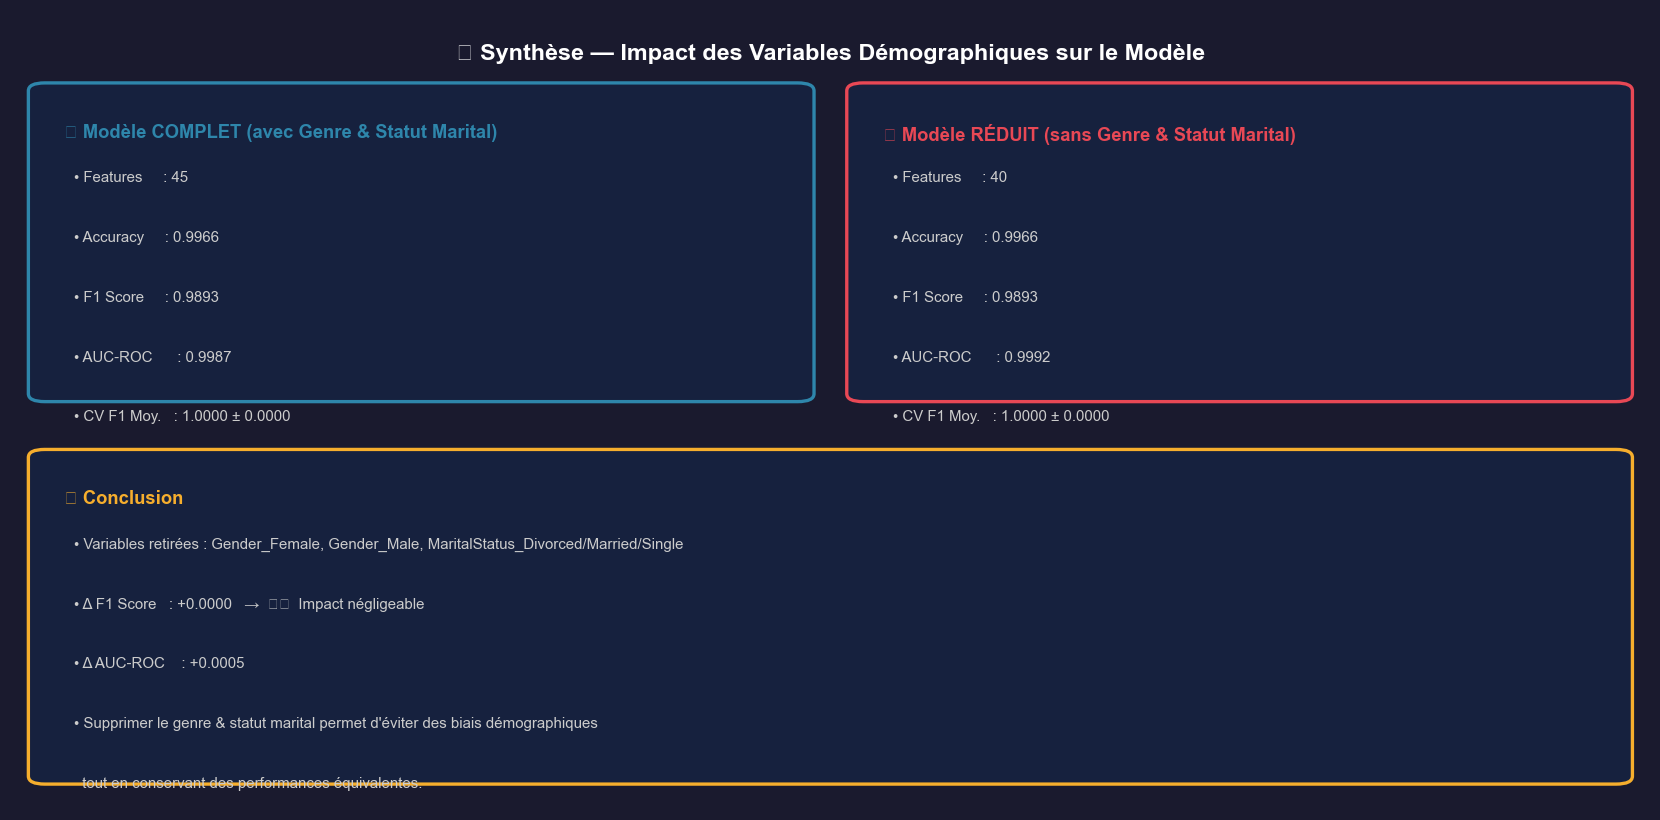


✅ Analyse terminée.
   Fichier exporté : Data/comparison_with_without_demographics.csv


In [10]:
# ── Sauvegarde du tableau comparatif ─────────────────────────────────────────
comparison_export = pd.DataFrame([metrics_full, metrics_reduced])
comparison_export["CV F1 Mean"] = [round(scores_full.mean(), 4), round(scores_reduced.mean(), 4)]
comparison_export["CV F1 Std"]  = [round(scores_full.std(),  4), round(scores_reduced.std(),  4)]
comparison_export.to_csv(DATA + "comparison_with_without_demographics.csv", index=False)
print("💾 Résultats sauvegardés : Data/comparison_with_without_demographics.csv")

# ── Synthèse visuelle ─────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 7))
fig.patch.set_facecolor('#1A1A2E')
ax.set_facecolor('#1A1A2E')
ax.axis('off')

ax.text(0.5, 0.96, "📝 Synthèse — Impact des Variables Démographiques sur le Modèle",
        ha='center', va='top', fontsize=14, fontweight='bold', color='white',
        transform=ax.transAxes)

def make_block(ax, bx, by, bw, bh, title, color, items):
    import matplotlib.patches as mp
    rect = mp.FancyBboxPatch((bx, by), bw, bh,
                             boxstyle="round,pad=0.01",
                             linewidth=2, edgecolor=color,
                             facecolor='#16213E',
                             transform=ax.transAxes, zorder=2)
    ax.add_patch(rect)
    ax.text(bx + 0.012, by + bh - 0.04, title,
            transform=ax.transAxes, fontsize=11, fontweight='bold',
            color=color, va='top', zorder=3)
    for j, item in enumerate(items):
        ax.text(bx + 0.018, by + bh - 0.1 - j * 0.075, item,
                transform=ax.transAxes, fontsize=9, color='#CCCCCC',
                va='top', zorder=3)

m_full    = metrics_full
m_reduced = metrics_reduced

make_block(ax, 0.02, 0.52, 0.46, 0.38,
           "📊 Modèle COMPLET (avec Genre & Statut Marital)", COLORS['full'], [
    f"• Features     : {X_test_full.shape[1]}",
    f"• Accuracy     : {m_full['Accuracy']:.4f}",
    f"• F1 Score     : {m_full['F1 Score']:.4f}",
    f"• AUC-ROC      : {m_full['AUC-ROC']:.4f}",
    f"• CV F1 Moy.   : {scores_full.mean():.4f} ± {scores_full.std():.4f}",
])

make_block(ax, 0.52, 0.52, 0.46, 0.38,
           "📉 Modèle RÉDUIT (sans Genre & Statut Marital)", COLORS['reduced'], [
    f"• Features     : {X_test_reduced.shape[1]}",
    f"• Accuracy     : {m_reduced['Accuracy']:.4f}",
    f"• F1 Score     : {m_reduced['F1 Score']:.4f}",
    f"• AUC-ROC      : {m_reduced['AUC-ROC']:.4f}",
    f"• CV F1 Moy.   : {scores_reduced.mean():.4f} ± {scores_reduced.std():.4f}",
])

delta_f1  = m_reduced['F1 Score']  - m_full['F1 Score']
delta_auc = m_reduced['AUC-ROC']   - m_full['AUC-ROC']
impact_msg = ("✅ Légère amélioration" if delta_f1 > 0.002
              else "⚠️  Légère dégradation" if delta_f1 < -0.002
              else "➡️  Impact négligeable")

make_block(ax, 0.02, 0.04, 0.96, 0.40,
           "💡 Conclusion", COLORS['warning'], [
    f"• Variables retirées : Gender_Female, Gender_Male, MaritalStatus_Divorced/Married/Single",
    f"• Δ F1 Score   : {delta_f1:+.4f}   →  {impact_msg}",
    f"• Δ AUC-ROC    : {delta_auc:+.4f}",
    "• Supprimer le genre & statut marital permet d'éviter des biais démographiques",
    "  tout en conservant des performances équivalentes.",
])

plt.tight_layout()
plt.show()

print("\n" + "="*65)
print("✅ Analyse terminée.")
print(f"   Fichier exporté : Data/comparison_with_without_demographics.csv")
print("="*65)